In [1]:
pip install numpy pandas matplotlib seaborn scikit-learn

Dataset Shape: (569, 30)

Class Distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64

Training samples: 455
Testing samples: 114

MODEL: SVM
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1-score : 0.9861
Log Loss : 0.0860

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


MODEL: Decision Tree
Accuracy : 0.9211
Precision: 0.9565
Recall   : 0.9167
F1-score : 0.9362
Log Loss : 1.9708

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.87      0.93      0.90        42
      Benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92   

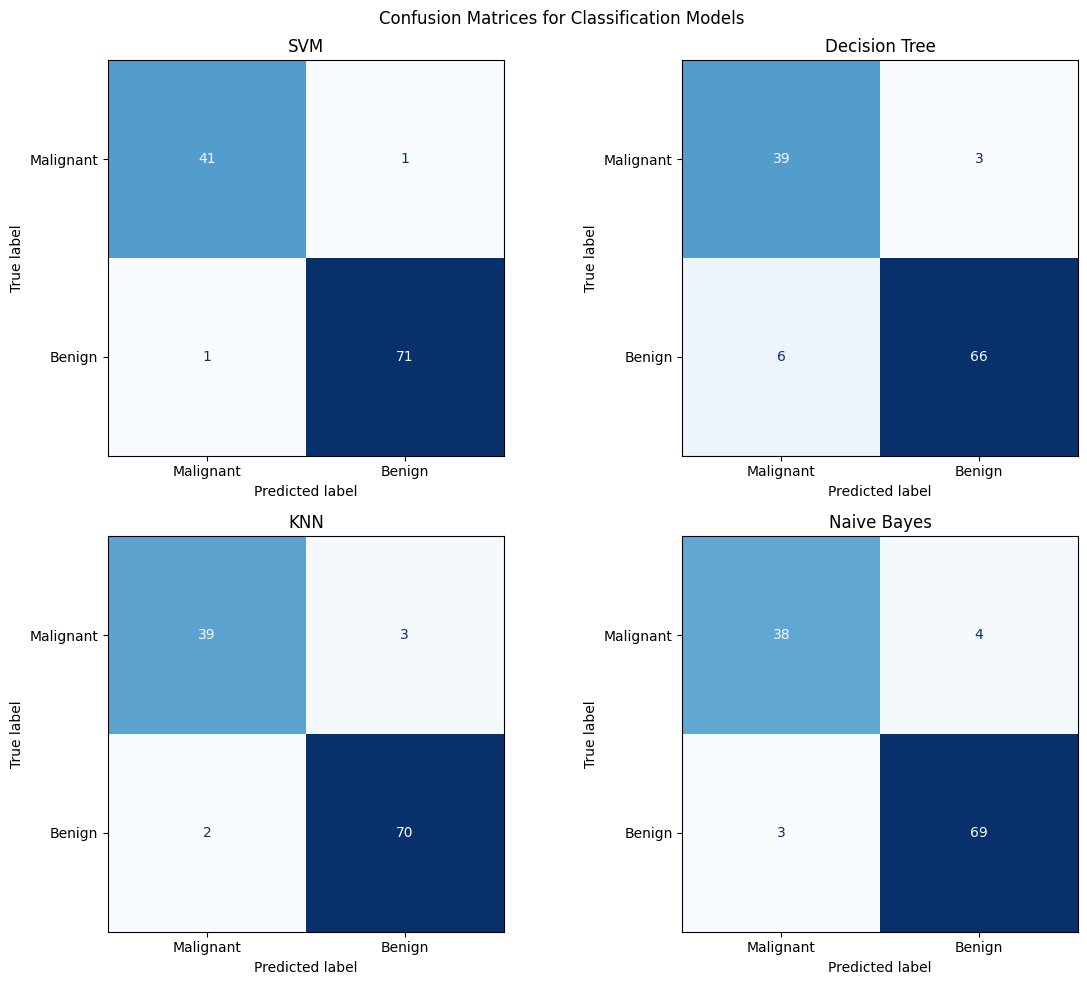

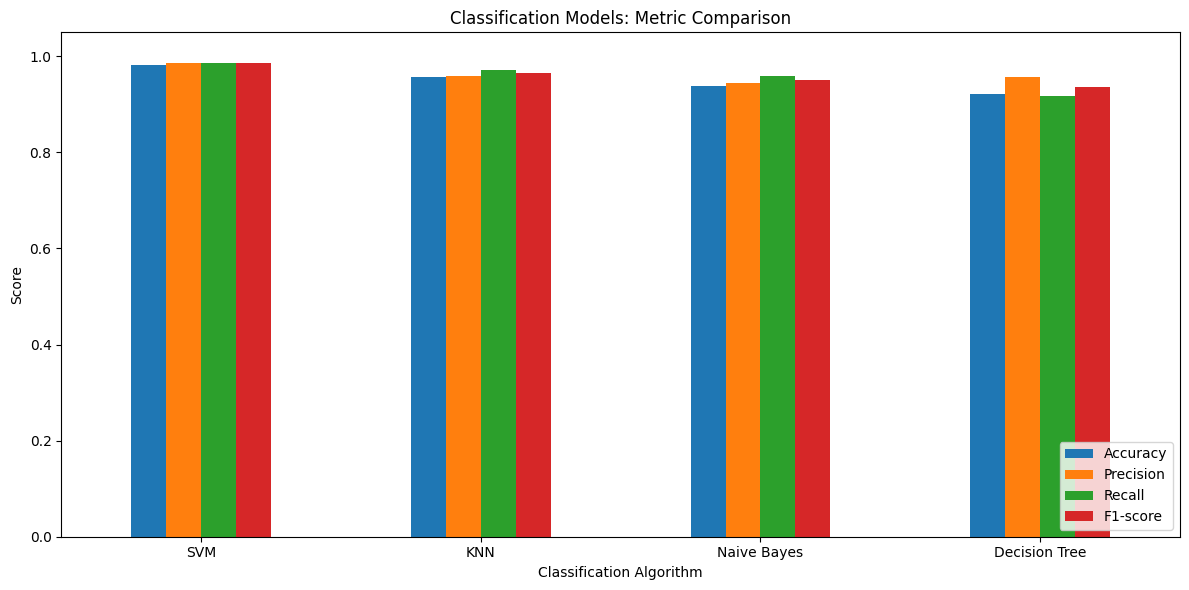

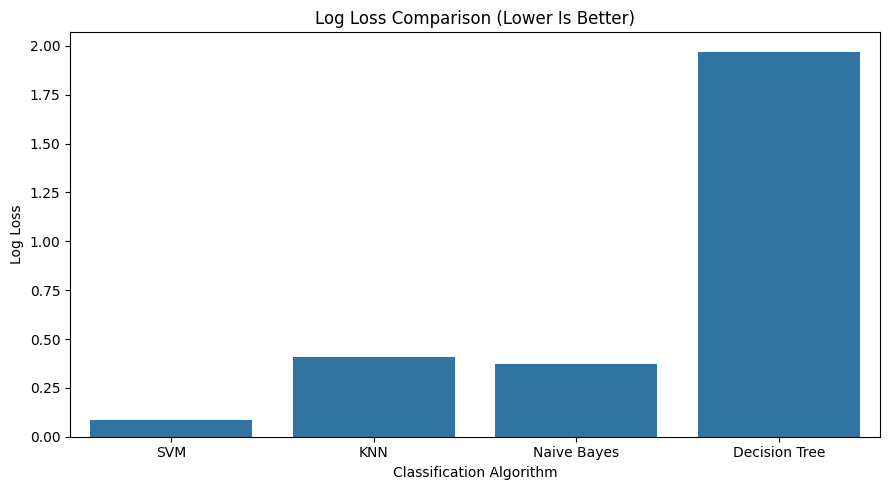


5-FOLD CROSS-VALIDATION RESULTS
        Model  Mean CV Accuracy  Std CV Accuracy
          SVM            0.9692           0.0146
Decision Tree            0.9231           0.0120
          KNN            0.9626           0.0112
  Naive Bayes            0.9407           0.0247

FINAL FINDINGS
Highest F1-score: SVM
Highest Accuracy: SVM
Lowest Log Loss: SVM

Experiment completed successfully.
Saved files:
- classification_results.csv
- cross_validation_results.csv
- confusion_matrices.png
- metric_comparison.png
- log_loss_comparison.png


In [2]:

# ============================================================
# Comparative Analysis of Classification Algorithms
# Algorithms: SVM, Decision Tree, KNN, Naive Bayes
# Dataset: Breast Cancer Wisconsin Dataset
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. Load dataset
# ------------------------------------------------------------

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset Shape:", X.shape)
print("\nClass Distribution:")
print(y.map({0: "Malignant", 1: "Benign"}).value_counts())

# ------------------------------------------------------------
# 2. Split into training and testing sets
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ------------------------------------------------------------
# 3. Define classification models
# Scaling is fitted only on training data through Pipeline.
# ------------------------------------------------------------

models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            weights="uniform"
        ))
    ]),

    "Naive Bayes": GaussianNB()
}

# ------------------------------------------------------------
# 4. Train models and calculate evaluation metrics
# ------------------------------------------------------------

results = []
predictions = {}
probabilities = {}

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict classes and class probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    predictions[name] = y_pred
    probabilities[name] = y_prob

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )
    loss = log_loss(y_test, y_prob, labels=[0, 1])

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Log Loss": loss
    })

    print(f"\n{'=' * 55}")
    print(f"MODEL: {name}")
    print(f"{'=' * 55}")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")
    print(f"Log Loss : {loss:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Malignant", "Benign"],
        zero_division=0
    ))

# ------------------------------------------------------------
# 5. Comparative performance table
# ------------------------------------------------------------

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

print("\n\nFINAL PERFORMANCE COMPARISON")
print(results_df.round(4).to_string(index=False))

results_df.to_csv("classification_results.csv", index=False)

# ------------------------------------------------------------
# 6. Confusion matrices
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Malignant", "Benign"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )
    ax.set_title(name)

plt.suptitle("Confusion Matrices for Classification Models")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 7. Metric comparison chart
# ------------------------------------------------------------

metric_columns = [
    "Accuracy", "Precision", "Recall", "F1-score"
]

plot_data = results_df.set_index("Model")[metric_columns]

plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05)
)

plt.title("Classification Models: Metric Comparison")
plt.ylabel("Score")
plt.xlabel("Classification Algorithm")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("metric_comparison.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 8. Log loss comparison
# Lower log loss is better.
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Log Loss"
)

plt.title("Log Loss Comparison (Lower Is Better)")
plt.ylabel("Log Loss")
plt.xlabel("Classification Algorithm")
plt.tight_layout()
plt.savefig("log_loss_comparison.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 9. Stratified 5-fold cross-validation
# Evaluate generalization using training data only.
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Std CV Accuracy": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

print("\n5-FOLD CROSS-VALIDATION RESULTS")
print(cv_df.round(4).to_string(index=False))

cv_df.to_csv("cross_validation_results.csv", index=False)

# ------------------------------------------------------------
# 10. Identify the best models by different criteria
# ------------------------------------------------------------

best_f1 = results_df.loc[
    results_df["F1-score"].idxmax()
]

best_accuracy = results_df.loc[
    results_df["Accuracy"].idxmax()
]

best_loss = results_df.loc[
    results_df["Log Loss"].idxmin()
]

print("\nFINAL FINDINGS")
print("Highest F1-score:", best_f1["Model"])
print("Highest Accuracy:", best_accuracy["Model"])
print("Lowest Log Loss:", best_loss["Model"])

print("\nExperiment completed successfully.")
print("Saved files:")
print("- classification_results.csv")
print("- cross_validation_results.csv")
print("- confusion_matrices.png")
print("- metric_comparison.png")
print("- log_loss_comparison.png")
